> **第二部分的历史方法记录｜归档说明（2026-10-28）**
> 本文保留当时的方法、代码与输出；“尚未拟合”等进度句只描述该阶段。最新结果见 [H0–H3 综合 Notebook](matching_h0_h3_results.ipynb) 与 [当前 README](README_zh.md)。第三部分尚未正式分析。
> 研究日志不是一键复现入口；尤其 observation_recovery 含昂贵采样和本地中间文件依赖，不要直接 Run All。

# Matching 机制分析：前期行为诊断

本笔记本复核已公开的行为汇总，补充反应标准、RT 条件选择结构及实验设计审查。所有新增结果均为探索性分析；不运行 HDDM，不修改原有数据、模型、结果或 README。不是新的机制鉴别结论。

在 `02_reanalysis_2026/` 或仓库根目录运行，需要 Python、NumPy、pandas、SciPy、Matplotlib 和 Jupyter。图表保存在笔记本输出中，不写入既有 Output。均以被试为推断单位，报告传统双侧 95% t 区间，未校正多重比较；这些区间不是后验可信区间。

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm, t
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if ROOT.name == '02_reanalysis_2026': ROOT = ROOT.parent
assert (ROOT/'01_reproduction_2020').is_dir(), 'Run from the repository root or 02_reanalysis_2026'
base = ROOT/'01_reproduction_2020'
inputs = {'wide': base/'Output/behavior/confirm/MS_match_behav_wide.csv',
          'raw': base/'Data/raw/confirm/MS_rep_matchingTask_raw.csv',
          'hddm': ROOT/'02_reanalysis_2026/Data/matching_input.csv'}
display(pd.DataFrame([{'input': str(p.relative_to(ROOT)), 'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in inputs.values()]))
print('numpy',np.__version__,'pandas',pd.__version__,'scipy',scipy.__version__,'matplotlib',matplotlib.__version__)
wide=pd.read_csv(inputs['wide']).set_index('Subject')
raw=pd.read_csv(inputs['raw'],keep_default_na=False)
raw=raw[raw.Subject.isin(wide.index)].copy()
fit=pd.read_csv(inputs['hddm'])
assert wide.index.nunique()==42 and len(raw)==25200
assert raw.groupby('Subject').size().eq(600).all()
conditions=['Good_Self','Bad_Self','Good_Other','Bad_Other']
labels=['Good-self','Bad-self','Good-other','Bad-other']
raw['condition']=raw.Morality+'_'+raw.Identity
raw['correct']=raw.ACC.eq(1)
def ci(x):
    x=pd.Series(x).dropna().astype(float)
    if len(x)<2: return pd.Series({'n':len(x),'mean':x.mean(),'lo':np.nan,'hi':np.nan})
    mean=x.mean(); half=t.ppf(.975,len(x)-1)*x.std(ddof=1)/np.sqrt(len(x))
    return pd.Series({'n':len(x),'mean':mean,'lo':mean-half,'hi':mean+half})
pd.set_option('display.max_rows',60)
pd.set_option('display.max_columns',14)

,input,sha256
0,01_reproduction_2020/Output/behavior/confirm/M...,2ad1d92d3828f474efd78956068320d49705b9a2bc84f5...
1,01_reproduction_2020/Data/raw/confirm/MS_rep_m...,ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee8...
2,02_reanalysis_2026/Data/matching_input.csv,eca399f3ee7931cd0a270283672f9469ee4f20b6db137a...


numpy 1.23.3 pandas 2.0.1 scipy 1.9.1 matplotlib 3.6.0


## 行为效应复核

沿用第一部分的 42 名被试及筛选规则：所有非 ACC=1 记录计为错误，只删除正确且 RT≤0.2 秒的试次。正确 RT 为被试内均值，以下组均值对被试等权。先逐单元验证原始数据与已保存表一致，再计算 Good-self−Bad-self 对比与两个刺激方向的效应差。

In [2]:
trad=raw[~(raw.correct & raw.RT.le(.2))].copy()
for (subject,direction,condition),g in trad.groupby(['Subject','Match','condition']):
    assert np.isclose(g.correct.mean(),wide.loc[subject,'ACC_'+direction+'_'+condition],atol=1e-10)
    assert np.isclose(g.loc[g.correct,'RT'].mean()*1000,wide.loc[subject,'RT_'+direction+'_'+condition],atol=1e-8)
behavior=[]
for condition,label in zip(conditions,labels):
    for direction in ['match','mismatch']:
        behavior.append(dict(condition=label,stimulus=direction,
            correct_RT_ms=wide['RT_'+direction+'_'+condition].mean(),
            accuracy_percent=100*wide['ACC_'+direction+'_'+condition].mean()))
behavior=pd.DataFrame(behavior)
display(behavior.round(3))
effects={}
for metric in ['RT','ACC']:
    scale=1 if metric=='RT' else 100
    for direction in ['match','mismatch']:
        effects[metric+'_'+direction]=scale*(wide[metric+'_'+direction+'_Good_Self']-wide[metric+'_'+direction+'_Bad_Self'])
    effects[metric+'_match_minus_mismatch']=effects[metric+'_match']-effects[metric+'_mismatch']
effects['dprime_historical']=wide.d_Good_Self-wide.d_Bad_Self
effect_table=pd.DataFrame({name:ci(x) for name,x in effects.items()}).T
display(effect_table.round(4))
assert np.isclose(effects['RT_match'].mean(),-82.56,atol=.01)
assert np.isclose(effects['RT_mismatch'].mean(),-15.27,atol=.01)

,condition,stimulus,correct_RT_ms,accuracy_percent
0,Good-self,match,637.837,90.267
1,Good-self,mismatch,732.149,79.103
2,Bad-self,match,720.397,79.397
3,Bad-self,mismatch,747.424,80.109
4,Good-other,match,681.645,83.081
5,Good-other,mismatch,738.946,78.177
6,Bad-other,match,707.206,81.004
7,Bad-other,mismatch,731.931,84.366


,n,mean,lo,hi
RT_match,42.0,-82.5600,-102.3540,-62.7660
RT_mismatch,42.0,-15.2746,-26.7952,-3.7540
RT_match_minus_mismatch,42.0,-67.2854,-83.7569,-50.8140
ACC_match,42.0,10.8700,7.3259,14.4142
ACC_mismatch,42.0,-1.0056,-4.7665,2.7554
ACC_match_minus_mismatch,42.0,11.8756,7.1327,16.6185
dprime_historical,42.0,0.5260,0.2792,0.7728


Mismatch 正确 RT 也有较小的 Good-self 优势；“Mismatch 没有行为优势”不是准确概括。正确率差异与正确 RT 必须联合解释，后者还受到正确反应条件化及超时筛选的影响。

## 无反应、按键与截止时间

原始程序审查发现：`getParams` 设置 TargetDur=0.1 秒、BlankDur=0.8–1.1 秒，主程序只初始化一次；Matching 循环未重新抽取 BlankDur。**按键轮询位于刺激消失的 Screen Flip 之后**，RT 则以刺激出现时刻为原点。因而不能把“RT 起算时刻”与“开始轮询时刻”等同。

无反应时 ACC=-1、Resp=NA；轮询持续更新 currentRT，故该 RT 近似记录截止附近的最后轮询时刻，而非一次选择反应。以下把每名被试无反应 RT 的中位数称为“截止代理值”。它不是精确的 TargetDur+BlankDur，仍受半帧修正、轮询时序与导出精度影响；不据此直接改似然或截断预测。

合法选择依据原始 CorrResp 和 Resp 解码，排除非 m/n 按键，而非把所有错误自动反编码。

In [3]:
raw['valid_choice']=raw.Resp.isin(['m','n']) & raw.ACC.isin([0,1]) & raw.RT.gt(0)
display(raw.groupby(['ACC','Resp'],dropna=False).size().rename('trials').reset_index())
deadline=raw[raw.ACC.eq(-1)].groupby('Subject').RT.agg(['size','min','median','max'])
deadline['spread_ms']=1000*(deadline['max']-deadline['min'])
display(deadline.round(4))
print('Omissions:',raw.ACC.eq(-1).sum(),'subjects:',len(deadline),'of',len(wide))
print('Deadline proxy range (s):',deadline['median'].min(),deadline['median'].max())
print('Largest within-subject spread (ms):',deadline.spread_ms.max())
exclusions=raw.assign(omission=raw.ACC.eq(-1),other_invalid=~raw.valid_choice & ~raw.ACC.eq(-1)).groupby(['Subject','condition','Match'])[['omission','other_invalid']].mean()
display((100*exclusions.groupby(['condition','Match']).mean()).round(3))
valid=raw[raw.valid_choice].copy()
valid['stim']=valid.Match.eq('match').astype(int)
valid['choice_match']=np.where(valid.stim.eq(1),valid.Resp.eq(valid.CorrResp),~valid.Resp.eq(valid.CorrResp)).astype(int)
assert (valid.Resp.eq(valid.CorrResp)==valid.correct).all()
assert len(valid)==len(fit)==24527
# Independent trial-level key-based decoding must match the current model input.
left=valid.sort_index()
assert np.array_equal(left.Subject.to_numpy(),fit.subj_idx.to_numpy())
assert np.array_equal(left.choice_match.to_numpy(),fit.response.to_numpy())
assert np.allclose(left.RT,fit.rt)

,ACC,Resp,trials
0,-1,NA,649
1,0,k,1
2,0,m,1971
3,0,n,1903
4,1,m,10363
5,1,n,10290
6,2,",<",3
7,2,h,6
8,2,j,3
9,2,space,2


,size,min,median,max,spread_ms
Subject,,,,,
7304,19,1.0329,1.0330,1.0330,0.1
7305,16,1.0841,1.0841,1.0841,0.0
7306,13,1.0850,1.0850,1.0850,0.0
7307,13,1.0841,1.0841,1.0841,0.0
7308,13,1.0850,1.0850,1.0850,0.0
7309,3,1.0850,1.0850,1.0850,0.0
7310,2,1.1430,1.1430,1.1430,0.0
7311,1,1.0841,1.0841,1.0841,0.0
7312,27,1.0841,1.0841,1.0841,0.0


Omissions: 649 subjects: 42 of 42
Deadline proxy range (s): 1.017 1.1831
Largest within-subject spread (ms): 0.39999999999995595


omission  other_invalid
condition  Match                            
Bad_Other  match        2.571          0.063
           mismatch     2.952          0.159
Bad_Self   match        2.635          0.159
           mismatch     2.984          0.032
Good_Other match        2.095          0.095
           mismatch     3.683          0.095
Good_Self  match        1.397          0.000
           mismatch     2.286          0.159

## SDT：敏感性与反应标准

H 为 Match 刺激上的 Match 选择率，F 为 Mismatch 刺激上的 Match 选择率。d′=Φ⁻¹(H)−Φ⁻¹(F)，c=−[Φ⁻¹(H)+Φ⁻¹(F)]/2；c<0 对应更倾向 Match。

分别计算历史口径与合法选择口径。历史口径严格复现第一部分：非正确反应均视为错误，仅修正 H=1 与 F=0；它会把 Mismatch 无反应算作 false alarm，**不宜把该 c 直接解释为真实选择偏向**。合法选择口径使用全部正 RT 合法反应，采用 (次数+0.5)/(试次数+1) 修正全部比率，并另做 RT>0.2 秒的描述性敏感性汇总。三者不能混作同一估计量。

In [4]:
sdt_rows=[]
for policy,data in [('historical',trad),('valid_choice',valid),('valid_RT_gt_0p2',valid[valid.RT.gt(.2)])]:
    for (subject,condition),g in data.groupby(['Subject','condition']):
        m=g.Match.eq('match'); nm=int(m.sum()); nn=int((~m).sum())
        hit=int(g.loc[m,'correct'].sum())
        fa=int((~g.loc[~m,'correct']).sum()) if policy=='historical' else int(g.loc[~m,'choice_match'].sum())
        if policy=='historical':
            h=hit/nm; f=fa/nn
            if h==1:h=1-1/(2*nm)
            if f==0:f=1/(2*nn)
        else:h=(hit+.5)/(nm+1); f=(fa+.5)/(nn+1)
        dp=norm.ppf(h)-norm.ppf(f); criterion=-(norm.ppf(h)+norm.ppf(f))/2
        assert np.isfinite([dp,criterion]).all()
        if policy=='historical':assert np.isclose(dp,wide.loc[subject,'d_'+condition],atol=1e-10)
        sdt_rows.append(dict(policy=policy,Subject=subject,condition=condition,n_match=nm,n_mismatch=nn,dprime=dp,c=criterion))
sdt=pd.DataFrame(sdt_rows)
display(sdt.groupby(['policy','condition'])[['dprime','c','n_match','n_mismatch']].mean().round(4))
sdt_effects=[]
for policy,g in sdt.groupby('policy'):
    for metric in ['dprime','c']:
        w=g.pivot(index='Subject',columns='condition',values=metric)
        sdt_effects.append(dict(policy=policy,metric=metric,**ci(w.Good_Self-w.Bad_Self)))
display(pd.DataFrame(sdt_effects).round(4))

dprime       c  n_match  n_mismatch
policy          condition                                      
historical      Bad_Other   2.0630  0.0534  74.9524     74.9524
                Bad_Self    1.7992  0.0123  75.0000     74.8810
                Good_Other  1.9129 -0.1261  74.9286     74.9524
                Good_Self   2.3252 -0.2985  74.9762     74.9524
valid_RT_gt_0p2 Bad_Other   2.2098  0.0734  72.9048     72.5952
                Bad_Self    1.9458  0.0128  72.9048     72.5714
                Good_Other  2.0527 -0.0933  73.2619     72.0952
                Good_Self   2.4286 -0.2895  73.9048     73.0714
valid_choice    Bad_Other   2.2067  0.0747  73.0238     72.6667
                Bad_Self    1.9446  0.0121  72.9048     72.7381
                Good_Other  2.0518 -0.0929  73.3571     72.1667
                Good_Self   2.4265 -0.2896  73.9524     73.1667

,policy,metric,n,mean,lo,hi
0,historical,dprime,42.0,0.5260,0.2792,0.7728
1,historical,c,42.0,-0.3109,-0.4199,-0.2019
2,valid_RT_gt_0p2,dprime,42.0,0.4827,0.2495,0.7160
3,valid_RT_gt_0p2,c,42.0,-0.3023,-0.4097,-0.1949
4,valid_choice,dprime,42.0,0.4820,0.2498,0.7142
5,valid_choice,c,42.0,-0.3018,-0.4091,-0.1945


## Mismatch 标签组成

关联条件按 Shape 编码。Mismatch 标签从其余三个类别中随机选择；因此不能仅按形状条件解释所有难度差异。表中分别报告标签配对数量与每个被试单元的最小试次数；每个形状含三类关系：仅身份不同、仅道德属性不同、两者均不同。

补充将三类标签关系等权汇总，与原有混合比例下的 Good-self−Bad-self 差异比较。这只是描述性标准化，不是因果校正；未平衡物理刺激或关联学习难度。

In [5]:
mapping={'moralSelf':('Good','Self'),'immoralSelf':('Bad','Self'),'moralOther':('Good','Other'),'immoralOther':('Bad','Other')}
mis=raw[raw.Match.eq('mismatch')].copy()
assert mis.Shape.ne(mis.Label).all()
mis['relation']=[('both' if mapping[s][0]!=mapping[l][0] and mapping[s][1]!=mapping[l][1] else 'valence_only' if mapping[s][0]!=mapping[l][0] else 'identity_only') for s,l in zip(mis.Shape,mis.Label)]
pair=mis.groupby(['Subject','condition','relation']).agg(n=('RT','size'),accuracy=('correct','mean'))
pair['correct_rt_ms']=1000*mis[mis.correct & mis.RT.gt(.2)].groupby(['Subject','condition','relation']).RT.mean()
display(pair.groupby(['condition','relation']).agg(total_trials=('n','sum'),min_trials_per_subject=('n','min'),mean_accuracy=('accuracy','mean'),mean_correct_rt_ms=('correct_rt_ms','mean')).round(3))
assert len(pair)==42*4*3 and pair.correct_rt_ms.notna().all()
balanced=pair.groupby(['Subject','condition'])[['accuracy','correct_rt_ms']].mean()
for metric,scale in [('accuracy',100),('correct_rt_ms',1)]:
    w=balanced[metric].unstack('condition')
    print('Equal relation weights:',metric,ci(scale*(w.Good_Self-w.Bad_Self)).round(4).to_dict())

total_trials  min_trials_per_subject  mean_accuracy   
condition  relation                                                             
Bad_Other  both                    980                      16          0.884  \
           identity_only          1078                      17          0.808   
           valence_only           1092                      19          0.838   
Bad_Self   both                   1034                      17          0.873   
           identity_only          1044                      20          0.811   
           valence_only           1072                      19          0.726   
Good_Other both                   1103                      15          0.867   
           identity_only           935                      18          0.679   
           valence_only           1112                      17          0.784   
Good_Self  both                   1031                      18          0.928   
           identity_only          1020                      16          0.615   
           valence_only           1099                      15          0.826   

                          mean_correct_rt_ms  
condition  relation                           
Bad_Other  both                      716.468  
           identity_only             749.182  
           valence_only              735.451  
Bad_Self   both                      729.872  
           identity_only             753.513  
           valence_only              762.553  
Good_Other both                      735.198  
           identity_only             752.116  
           valence_only              739.858  
Good_Self  both                      714.636  
           identity_only             750.619  
           valence_only              738.321

Equal relation weights: accuracy {'n': 42.0, 'mean': -1.3628, 'lo': -5.1464, 'hi': 2.4209}
Equal relation weights: correct_rt_ms {'n': 42.0, 'mean': -14.1208, 'lo': -26.1079, 'hi': -2.1337}


## RT 条件选择曲线（描述性 CBF）

本节明确使用操作性定义，不将曲线视为 z/dc 的独立识别工具。合法选择按“被试×关联条件”混合两种刺激方向后，以 RT 三分位分箱（保留并列值，不人为拆开），每箱分别计算 P(Match选择|Match刺激) 与 P(Match选择|Mismatch刺激)。

平衡方向的偏向指标 B=0.5×[上述两项概率]；B>0.5 表示等权刺激方向下更偏向 Match。这避免箱内刺激比例改变直接驱动总体 Match 选择率，但不能消除条件化 RT、难度或超时造成的影响。横轴为相对 RT 分箱，不是跨被试相同的绝对时刻；表中另列平均 RT（毫秒）。图的区间为被试间 95% t 区间。另列五分位箱试次数审查，不挑选最有利的分箱结果。

min_n  median_n  mean_rt_ms
condition  bin stim                             
Bad_Other  1   0         7      21.5      594.58
               1        18      27.0      587.33
           2   0        16      24.0      705.18
               1        17      24.0      704.19
           3   0        16      28.0      849.26
               1        11      21.0      842.81
Bad_Self   1   0        11      21.0      599.53
               1        19      27.5      597.28
           2   0        17      25.0      719.20
               1        18      23.0      719.02
           3   0        17      27.0      864.07
               1        15      22.0      864.20
Good_Other 1   0         5      19.5      580.14
               1        16      29.0      566.60
           2   0        13      25.0      699.06
               1        11      24.0      694.37
           3   0        20      28.0      849.68
               1         4      20.0      846.58
Good_Self  1   0         5      14.5      558.67
               1        24      35.0      552.00
           2   0        18      25.0      669.96
               1        14      24.0      662.11
           3   0        21      34.0      817.69
               1         4      14.5      804.01

3 bins: minimum cell size 4 ; cells below 10 trials 17 of 1008
5 bins: minimum cell size 1 ; cells below 10 trials 195 of 1680


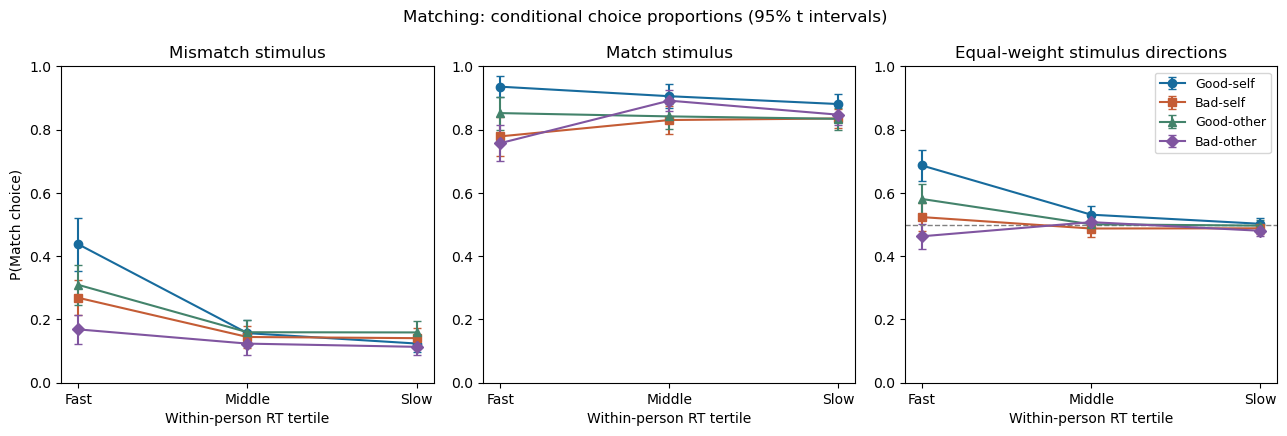

p_match_given_mismatch  p_match_given_match  balanced_bias
condition  bin                                                            
Bad_Other  1                    0.1686               0.7571         0.4628
           2                    0.1236               0.8916         0.5076
           3                    0.1134               0.8471         0.4803
Bad_Self   1                    0.2684               0.7786         0.5235
           2                    0.1445               0.8303         0.4874
           3                    0.1409               0.8352         0.4880
Good_Other 1                    0.3093               0.8522         0.5808
           2                    0.1596               0.8418         0.5007
           3                    0.1590               0.8341         0.4965
Good_Self  1                    0.4376               0.9357         0.6866
           2                    0.1567               0.9056         0.5311
           3                    0.1239               0.8808         0.5023

,n,mean,lo,hi,bins
bin,,,,,
1,42.0,0.1631,0.1116,0.2146,3
2,42.0,0.0437,0.0115,0.0759,3
3,42.0,0.0143,-0.0103,0.0388,3


,n,mean,lo,hi,bins
bin,,,,,
1,42.0,0.1837,0.1203,0.2471,5
2,42.0,0.1393,0.0935,0.1851,5
3,42.0,0.0420,0.0041,0.0798,5
4,42.0,0.0015,-0.0311,0.0340,5
5,42.0,0.0194,-0.0126,0.0514,5


In [6]:
def binned_choices(data,q):
    groups=[]
    for (subject,condition),g in data.groupby(['Subject','condition']):
        g=g.copy();g['bin']=pd.qcut(g.RT,q,labels=False,duplicates='drop')+1
        assert g['bin'].nunique()==q
        groups.append(g)
    b=pd.concat(groups)
    counts=b.groupby(['Subject','condition','bin','stim']).agg(n=('RT','size'),p=('choice_match','mean'),rt_ms=('RT',lambda x:1000*x.mean()))
    assert len(counts)==42*4*q*2
    p=counts.p.unstack('stim');p.columns=['p_match_given_mismatch','p_match_given_match']
    p['balanced_bias']=p.mean(axis=1)
    return counts,p
counts,cbf=binned_choices(valid,3)
counts5,cbf5=binned_choices(valid,5)
display(counts.groupby(['condition','bin','stim']).agg(min_n=('n','min'),median_n=('n','median'),mean_rt_ms=('rt_ms','mean')).round(2))
for q,cnt in [(3,counts),(5,counts5)]:
    print(q,'bins: minimum cell size',cnt.n.min(),'; cells below 10 trials',int(cnt.n.lt(10).sum()),'of',len(cnt))
fig,axes=plt.subplots(1,3,figsize=(13,4.4),sharex=True)
for condition,label,color,marker in zip(conditions,labels,['#176B9D','#C45C35','#43836B','#8055A0'],['o','s','^','D']):
    part=cbf.xs(condition,level='condition')
    for ax,metric,title in zip(axes,cbf.columns,['Mismatch stimulus','Match stimulus','Equal-weight stimulus directions']):
        stats=part.groupby('bin')[metric].apply(ci).unstack()
        ax.errorbar(stats.index,stats['mean'],yerr=[stats['mean']-stats.lo,stats.hi-stats['mean']],label=label,color=color,marker=marker,capsize=3)
        ax.set_title(title);ax.set_xlabel('Within-person RT tertile');ax.set_xticks([1,2,3],['Fast','Middle','Slow']);ax.set_ylim(0,1)
axes[0].set_ylabel('P(Match choice)');axes[2].axhline(.5,color='gray',ls='--',lw=1)
axes[2].legend(fontsize=9);fig.suptitle('Matching: conditional choice proportions (95% t intervals)',fontsize=12)
fig.tight_layout();plt.show()
display(cbf.groupby(['condition','bin']).mean().round(4))
# Paired Good-self minus Bad-self bias contrasts; unadjusted exploratory intervals.
for q,table in [(3,cbf),(5,cbf5)]:
    w=table.balanced_bias.unstack('condition');diff=w.Good_Self-w.Bad_Self
    display(diff.groupby('bin').apply(ci).unstack().assign(bins=q).round(4))

### 稀疏单元与极快反应敏感性

主图保留全部被试。补充仅纳入 Self 两条件所有三分位单元均至少有 10 次合法反应的被试，保证各箱使用同一批被试；该阈值只是透明的描述性检查，不是有效样本量标准，也不能替代原始全样本分析。另外排除 RT≤0.2 秒后重新分箱。

In [7]:
# Retain the same participants across all three bins in each sparse-cell sensitivity check.
def summarize_bias_differences(table, subjects=None):
    w=table.balanced_bias.unstack('condition')
    if subjects is not None:w=w[w.index.get_level_values('Subject').isin(subjects)]
    return (w.Good_Self-w.Bad_Self).groupby('bin').apply(ci).unstack()
self_counts=counts.reset_index().query("condition in ['Good_Self','Bad_Self']")
min_self=self_counts.groupby('Subject').n.min()
kept=min_self[min_self>=10].index
print('At least 10 trials in every Self condition x bin x stimulus cell; same subjects in all bins:',len(kept),'of 42')
display(summarize_bias_differences(cbf,kept).round(4))
_,cbf_no_fast=binned_choices(valid[valid.RT.gt(.2)],3)
print('RT > 0.2 s, bins recomputed:')
display(summarize_bias_differences(cbf_no_fast).round(4))


At least 10 trials in every Self condition x bin x stimulus cell; same subjects in all bins: 34 of 42


,n,mean,lo,hi
bin,,,,
1,34.0,0.1490,0.0919,0.2060
2,34.0,0.0348,-0.0032,0.0728
3,34.0,0.0106,-0.0175,0.0387


RT > 0.2 s, bins recomputed:


,n,mean,lo,hi
bin,,,,
1,42.0,0.1636,0.1118,0.2154
2,42.0,0.0430,0.0103,0.0758
3,42.0,0.0143,-0.0100,0.0386


## 本次诊断的结果与边界

- 行为汇总逐被试、逐条件与第一部分保存表一致。Good-self−Bad-self 正确 RT 差为 Match −82.56 ms、Mismatch −15.27 ms；正确率差分别为 +10.87 和 −1.01 百分点。后者的 95% 区间跨零，不能表述为已确定的负向效应。
- 合法选择口径的 d′ 差为 +0.482 [0.250, 0.714]，c 差为 −0.302 [−0.409, −0.195]。历史 d′ 差 +0.526 同样复核一致；口径与极端比率修正不同，不能把两者的差异全归因于超时。
- Good-self 相对 Bad-self 的平衡 Match 选择率差，在快速、中间、慢速三箱分别为 +16.31、+4.37、+1.43 百分点。快速箱的差异在排除极快反应、以及保留 34 名全部 Self 单元至少 10 次反应的被试后仍存在。三分位共有 17/1008 单元不足 10 次，五分位为 195/1680；尾部及细分箱解释应谨慎。中间与慢速箱结果不能仅凭显著与不显著之别断言存在箱间差异。
- 42 名被试共有 649 条无反应记录。各被试无反应 RT 中位数在 1.0170–1.1831 秒之间，最大被试内跨度 0.4 ms；这支持使用截止附近代理值开展后续核查，但未恢复精确逐次实验设置。
- Good-self Mismatch 的三类标签关系正确率差异很大：仅身份不同约 61.5%，仅道德属性不同约 82.6%，两者均不同约 92.8%。三类关系等权后，Good-self−Bad-self 正确 RT 差仍为 −14.12 ms [−26.11, −2.13]，正确率差为 −1.36 百分点 [−5.15, 2.42]。随机标签比例的不平衡不足以消除这一描述性 RT 差异，但关系难度仍需进入预测检验。

这些观察约束了模型需要解释的行为，没有识别唯一心理机制。特别是快反应偏向不直接证明起点偏置；选择条件化、刺激组成、先验和观测窗口都可能影响曲线。下一步应先确定观测过程与竞争模型的约束，再评估是否需要新拟合。


## 竞争假设与下一步

| 假设 | 需要约束的条件效应 | 必须解释的行为 | 目前不能断言什么 |
|---|---|---|---|
| H1：辨别效率 | 只允许 Good-self 对比进入 v，相关 dc 对比固定为零 | 两个方向的选择率和正确/错误 RT 联合分布 | 行为不对称本身不否定 H1，必须检验具体约束模型 |
| H2：漂移偏置 | 只允许相关 dc 对比，相关 v 对比固定为零 | Match 优势较大，同时 Mismatch 正确 RT 略快 | 正确 RT 是条件化统计量，不能仅凭其方向否定 H2 |
| H3：共同变化 | 同时允许 v 与 dc 的相关对比 | 上述联合模式及 RT 条件选择曲线 | 当前 M4 与其相容，不代表优于 H1/H2 |
| H4：起点偏置 | 共享 z 作为任务偏置；条件效应需另有事前线索依据 | 快慢反应中的选择结构 | z=0.568 不能直接解释为 Good-self 特异性起点偏好 |

下一阶段首先核对保存的实验参数或日志，评价无反应 RT 截止代理值是否足以支持观测过程建模；同时把 Mismatch 的标签关系纳入诊断性预测。定义共同的观测窗口、无反应处理和先验后，再设计 H1/H2/H3 的模拟与可辨识性预检。预测区分度不足时，应报告现有设计的限制，而不是继续堆叠拟合。

本笔记本没有执行新的 PPC、MCMC、参数恢复、模型恢复或正式模型比较；没有修改此前的估计及其限制。

## 程序来源与审查范围

- [Moral_self_asso_exp7_rep_getParams.m](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_getParams.m)：读取于 2026-10-24；SHA-256 `d66aed69222e52caa0ad94283c79d0f5a4e8a5fd711616cd76f1f6cee82208b2`。
- [Moral_self_asso_exp7_rep_match.m](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_match.m)：读取于 2026-10-24；SHA-256 `f6a8a0f0db7d58b4253e56360b7a5c233c2304c94ef56dcaf90cc829bfc28dd1`。
- [Moral_self_asso_exp7_rep_MainProc.m](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Procedure/confirmStudy_proc/Moral_self_asso_exp7_rep_MainProc.m)：读取于 2026-10-24；SHA-256 `09bb9b1ed971901446dcb13fa56371060caf5d720966b391cae8ffaeea048854`。

getParams 的 164、166 行设置刺激与空白时长；MainProc 第 102 行初始化参数；match 第 203–221 行选择错误标签，第 231–264 行规定刺激消失、按键轮询和 RT 记录。代码审查说明公开程序的行为，不证明每名被试运行了完全相同的版本。上述源程序只读核查，未复制进分析目录；运行本笔记本不依赖联网。

SDT 的 c 是选择分布的描述指标，不等于 DDM 的 dc。关于 DDM 中起点、漂移与 RT 分布的关系，可参阅 [Ratcliff & McKoon (2008)](https://pubmed.ncbi.nlm.nih.gov/18085991/)。